# Chapitre 7 - Cours 2 : goulots mémoire, représentations numériques et quantification

Le livre consacre une longue section, *Memory Bottlenecks*, à la question qui conditionne
toutes les techniques de finetuning modernes : **combien de mémoire faut-il**, et
pourquoi bien plus pour entraîner que pour servir un modèle ? Ce notebook en reprend les
sous-sections *Backpropagation and Trainable Parameters*, *Memory Math*, *Numerical
Representations* et *Quantization* (avec *Inference quantization* et *Training
quantization*), en remplaçant les ordres de grandeur par des calculs et des **mesures**
sur le GPU :

1. rétropropagation et paramètres entraînables (un réseau à trois paramètres, à la main) ;
2. le calcul de mémoire : inférence, entraînement, activations (calculateur du module) ;
3. mesures réelles de la mémoire GPU d'un pas d'entraînement (GPT-2, Qwen2.5-0.5B) et
   gradient checkpointing ;
4. représentations numériques : FP32, TF32, FP16, BF16, FP8, INT8, INT4 (bits, plages,
   précision, erreurs d'arrondi, précision mixte) ;
5. quantification : absmax, zéro-point, par groupe (écrites à la main) ;
6. quantifier de vrais poids (Qwen2.5-0.5B) : distributions, NF4, erreurs ;
7. impact sur la perplexité, et vraie quantification avec bitsandbytes ;
8. entraîner en basse précision : PTQ, QAT et précision mixte.

In [1]:
import gc
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie.plotting import (INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch07_finetuning as c7

warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", message=".*MatMul8bitLt.*")
c7.setup_style()
llm.seed_everything(0)
GB = 1e9

## 1. Rétropropagation et paramètres entraînables (section *Backpropagation and Trainable Parameters*)

**Le problème.** À l'inférence, un paramètre n'occupe que sa propre place. À
l'entraînement, chaque paramètre **entraînable** traîne avec lui des valeurs
supplémentaires. Pour comprendre lesquelles, déroulons un pas d'entraînement sur le plus
petit réseau possible, comme la figure 7-4 du livre : trois paramètres $w_1, w_2, w_3$ et
une non-linéarité $\sigma$ (sigmoïde) :
$$h = w_1 x + w_2, \qquad a = \sigma(h), \qquad \hat y = w_3\, a, \qquad L = (\hat y - y)^2.$$

- **Passe avant** : on calcule $h, a, \hat y, L$ et l'on **garde** $x, h, a$ en mémoire
  (ce sont les **activations**, nécessaires à la passe arrière).
- **Passe arrière** : la règle de la chaîne donne un **gradient** par paramètre
  entraînable : $\partial L/\partial \hat y = 2(\hat y - y)$, puis
  $\partial L/\partial w_3 = 2(\hat y - y)\,a$,
  $\partial L/\partial w_1 = 2(\hat y - y)\,w_3\,\sigma'(h)\,x$ et
  $\partial L/\partial w_2 = 2(\hat y - y)\,w_3\,\sigma'(h)$, avec $\sigma'(h) = a(1-a)$.
- **Mise à jour** par l'optimiseur. **Adam** garde, pour chaque paramètre, deux moyennes
  mobiles : $m \leftarrow \beta_1 m + (1-\beta_1) g$ (moment d'ordre 1) et
  $v \leftarrow \beta_2 v + (1-\beta_2) g^2$ (moment d'ordre 2), puis
  $w \leftarrow w - \eta\, \hat m / (\sqrt{\hat v} + \epsilon)$.

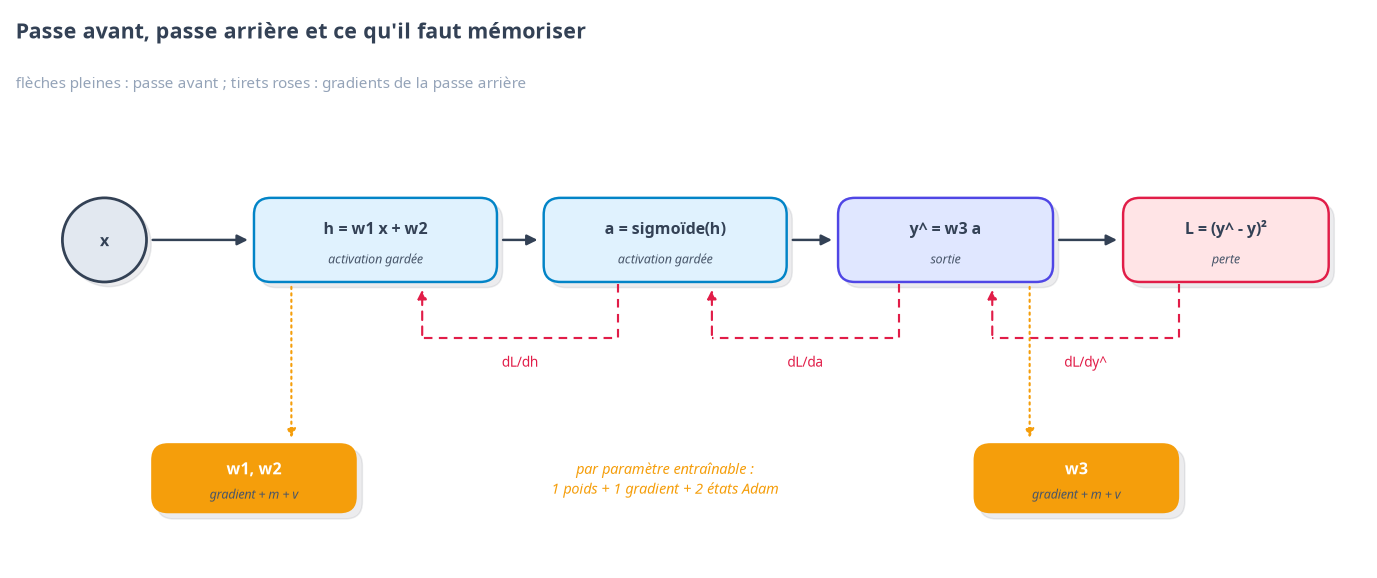

In [2]:
d = Diagram(14.5, 5.0, title="Passe avant, passe arrière et ce qu'il faut mémoriser",
            subtitle="flèches pleines : passe avant ; tirets roses : gradients de la passe arrière")
Y = 3.5
d.box("x", 1.0, Y, "x", color=SLATE, kind="circle", w=0.9)
d.box("h", 3.9, Y, "h = w1 x + w2", sub="activation gardée", color=SKY, w=2.6)
d.box("a", 7.0, Y, "a = sigmoïde(h)", sub="activation gardée", color=SKY, w=2.6)
d.box("y", 10.0, Y, "y^ = w3 a", sub="sortie", color=INDIGO, w=2.3)
d.box("L", 13.0, Y, "L = (y^ - y)²", sub="perte", color=ROSE, w=2.2)
for a_, b_ in [("x", "h"), ("h", "a"), ("a", "y"), ("y", "L")]:
    d.arrow(a_, b_)
for x1, x2, lab in [(13.0, 10.0, "dL/dy^"), (10.0, 7.0, "dL/da"), (7.0, 3.9, "dL/dh")]:
    d.line([(x1 - 0.5, Y - 0.47), (x1 - 0.5, Y - 1.05), (x2 + 0.5, Y - 1.05), (x2 + 0.5, Y - 0.5)], color=ROSE, style="dashed", lw=1.4)
    d.note((x1 + x2) / 2, Y - 1.3, lab, color=ROSE, fontsize=9, style="normal")
d.box("w12", 2.6, 0.95, "w1, w2", sub="gradient + m + v", color=AMBER, kind="tag", w=2.2, h=0.75)
d.box("w3", 11.4, 0.95, "w3", sub="gradient + m + v", color=AMBER, kind="tag", w=2.2, h=0.75)
d.line([(3.0, Y - 0.47), (3.0, 1.35)], color=AMBER, style="dotted", lw=1.4)
d.line([(10.9, Y - 0.47), (10.9, 1.35)], color=AMBER, style="dotted", lw=1.4)
d.note(7.0, 0.95, "par paramètre entraînable :\n1 poids + 1 gradient + 2 états Adam", color=AMBER, fontsize=9.5)
d.show()

In [3]:
sig = lambda z: 1 / (1 + np.exp(-z))


def forward(w, x, y):
    h = w[0] * x + w[1]; a = sig(h); yh = w[2] * a
    return (yh - y) ** 2, (h, a, yh)


def backward(w, x, y):
    L, (h, a, yh) = forward(w, x, y)
    dy = 2 * (yh - y); dh = dy * w[2] * a * (1 - a)
    return np.array([dh * x, dh, dy * a])


w = np.array([0.5, -0.3, 1.2]); x, y = 2.0, 1.5
g = backward(w, x, y)
eps = 1e-6
g_num = np.array([(forward(w + eps * np.eye(3)[i], x, y)[0] - forward(w - eps * np.eye(3)[i], x, y)[0]) / (2 * eps)
                  for i in range(3)])
# un pas d'Adam (beta1 = 0.9, beta2 = 0.999, lr = 0.1)
m = 0.1 * g; v = 0.001 * g ** 2
m_hat, v_hat = m / (1 - 0.9), v / (1 - 0.999)
w_new = w - 0.1 * m_hat / (np.sqrt(v_hat) + 1e-8)
pd.DataFrame({"poids w": w, "gradient (règle de la chaîne)": g, "gradient (diff. finies)": g_num,
              "état Adam m": m, "état Adam v": v, "w après 1 pas": w_new},
             index=["w1", "w2", "w3"]).round(5)

,poids w,gradient (règle de la chaîne),gradient (diff. finies),état Adam m,état Adam v,w après 1 pas
w1,0.5,-0.74301,-0.74301,-0.07430,0.00055,0.6
w2,-0.3,-0.37151,-0.37151,-0.03715,0.00014,-0.2
w3,1.2,-0.93302,-0.93302,-0.09330,0.00087,1.3


Les gradients analytiques coïncident avec les différences finies. Au premier pas, Adam
déplace chaque poids d'environ $\eta$ dans la direction opposée au gradient (le rapport
$\hat m/\sqrt{\hat v}$ vaut $\pm 1$), quelle que soit l'échelle du gradient. Le bilan
mémoire est le cœur du chapitre : **par paramètre entraînable**, il faut stocker le poids,
son gradient et (avec Adam) deux états, soit quatre valeurs au lieu d'une ; un paramètre
**gelé** ne coûte que son poids. Moins de paramètres entraînables, c'est l'idée de PEFT
(cours 3).

> **À retenir.** Inférence = passe avant seule. Entraînement = passe avant (activations
> gardées) + passe arrière (un gradient par paramètre entraînable) + optimiseur (0 état
> pour SGD, 1 pour le momentum, 2 pour Adam).

## 2. Le calcul de mémoire (section *Memory Math*)

**Inférence.** Avec $N$ paramètres de $M$ octets chacun, les poids occupent $N \times M$.
Il faut y ajouter les activations et le cache clé-valeur (chapitre 9) ; le livre propose
la règle empirique de 20 % :
$$\text{mémoire}_{\text{inférence}} \approx N \times M \times 1{,}2.$$
Exemple du livre : 13 milliards de paramètres en 16 bits, $26 \text{ Go} \times 1{,}2 = 31{,}2$ Go.

**Entraînement.**
$$\text{mémoire}_{\text{entraînement}} = \text{poids} + \text{activations} + \text{gradients} + \text{états de l'optimiseur}.$$
Le livre compte, pour Adam, trois valeurs de 2 octets par paramètre entraînable (un
gradient et deux états) : un 13 B entièrement entraîné demande $13 \cdot 10^9 \times 3 \times 2 = 78$ Go
en plus des poids ; avec seulement 1 milliard de paramètres entraînables, 6 Go.

En pratique, la recette de **précision mixte** la plus répandue (poids et gradients en
16 bits, copie « maîtresse » des poids et états d'Adam en 32 bits) coûte
$2 + 2 + 4 + 4 + 4 = 16$ octets par paramètre entraînable. `c7.training_memory` implémente
les deux conventions (`recipe="livre"` et `recipe="mixte"`).

In [4]:
rows = []
for name, spec in c7.MODEL_SPECS.items():
    N = spec.n_params
    rows.append({"modèle": name,
                 "inférence 16 bits (x1,2)": c7.inference_memory(N, 2) / GB,
                 "LoRA (1 % entraînable, livre)": c7.training_memory(N, 0.01 * N)["total"] / GB,
                 "finetuning complet (livre)": c7.training_memory(N)["total"] / GB,
                 "finetuning complet (précision mixte)": c7.training_memory(N, recipe="mixte")["total"] / GB})
mem = pd.DataFrame(rows).set_index("modèle")
mem.round(1)

,"inférence 16 bits (x1,2)","LoRA (1 % entraînable, livre)",finetuning complet (livre),finetuning complet (précision mixte)
modèle,,,,
GPT-2 (124M),0.3,0.3,1.0,2.0
Qwen2.5-0.5B,1.2,1.0,4.0,7.9
Qwen2.5-1.5B,3.7,3.2,12.3,24.6
Llama 2-7B,16.2,13.9,53.9,107.8
Llama 2-13B,31.2,26.8,104.0,208.0
Llama 2-70B,165.6,142.1,552.0,1104.0
GPT-3 (175B),420.0,360.5,1400.0,2800.0


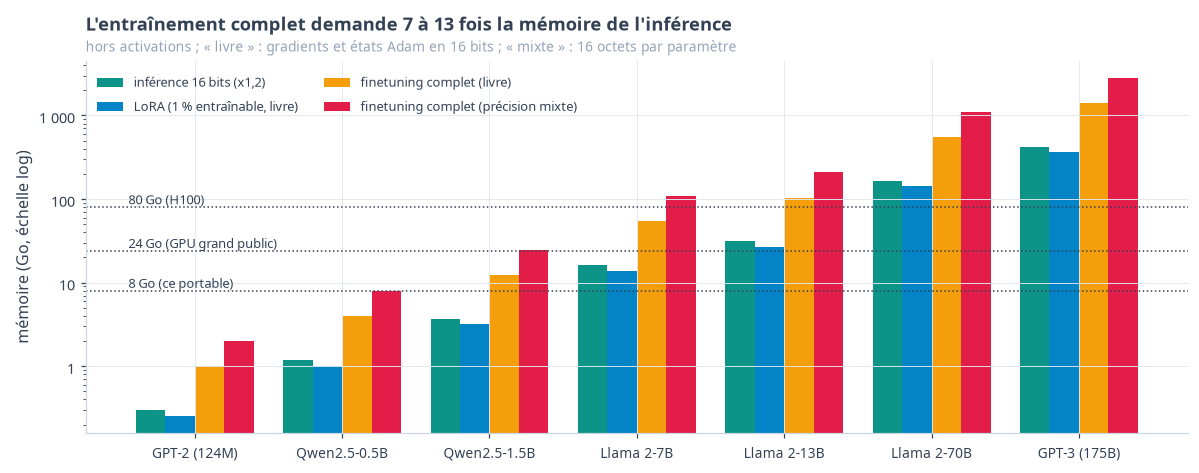

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.4))
cols = mem.columns
xk = np.arange(len(mem))
for j, (c, col) in enumerate(zip(cols, [TEAL, SKY, AMBER, ROSE])):
    ax.bar(xk + (j - 1.5) * 0.2, mem[c], 0.2, color=col, label=c)
ax.set_yscale("log"); c7.sci_log(ax, "y"); c7.plain_log(ax, "y")
for cap, lab in [(8, "8 Go (ce portable)"), (24, "24 Go (GPU grand public)"), (80, "80 Go (H100)")]:
    ax.axhline(cap, color=SLATE, ls=":", lw=1)
    ax.text(-0.45, cap * 1.08, lab, fontsize=8.5, color=SLATE, ha="left")
ax.set_xticks(xk, mem.index, fontsize=9); ax.set_ylabel("mémoire (Go, échelle log)")
ax.legend(ncol=2, fontsize=8.5, loc="upper left", bbox_to_anchor=(0.0, 1.0))
c7.title_sub(ax, "L'entraînement complet demande 7 à 13 fois la mémoire de l'inférence",
             "hors activations ; « livre » : gradients et états Adam en 16 bits ; « mixte » : 16 octets par paramètre")
plt.tight_layout(); plt.show()

Sur ce GPU de 8 Go, l'inférence est possible jusqu'à environ 3 milliards de paramètres en
16 bits ; le finetuning **complet** ne passe que pour les modèles de quelques centaines de
millions de paramètres. L'exemple du livre se retrouve : un 7 B en finetuning complet
demande $14 + 42 = 56$ Go selon sa convention, hors de portée des GPU grand public.

**Les activations.** Elles croissent linéairement avec la taille du lot $b$ et (au moins)
linéairement avec la longueur $s$ de la séquence. Korthikanti et al. (2022), dont le livre
reproduit la figure 7-5, donnent pour un bloc transformer en 16 bits de dimension $h$ à $a$
têtes :
$$\text{activations par couche} \approx s\,b\,h\left(34 + \frac{5\,a\,s}{h}\right) \text{ octets}.$$
Le terme en $s^2$ vient des matrices d'attention. Le **gradient checkpointing** (ou
recalcul des activations) ne garde que l'entrée de chaque bloc ($2sbh$ octets) et
recalcule le reste pendant la passe arrière : moins de mémoire, plus de calcul.

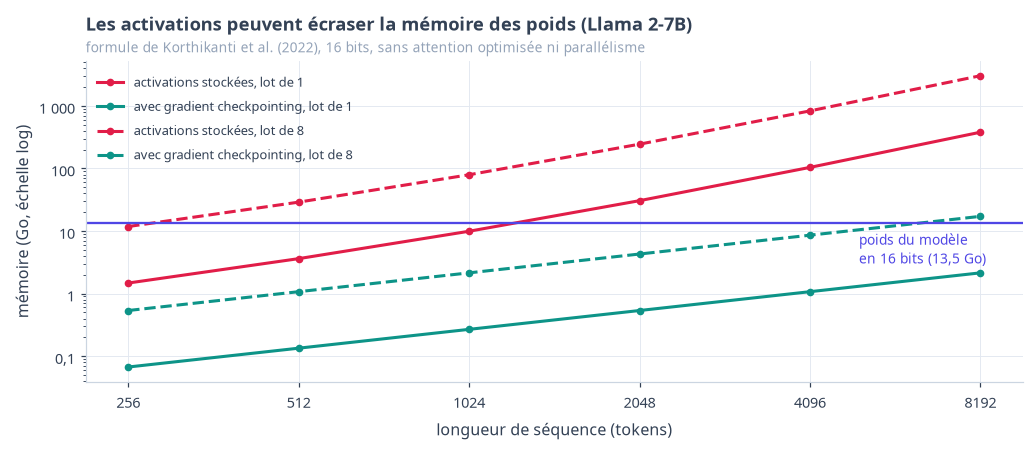

In [6]:
spec = c7.MODEL_SPECS["Llama 2-7B"]
seqs = np.array([256, 512, 1024, 2048, 4096, 8192])
fig, ax = plt.subplots(figsize=(9.5, 4.2))
for b, ls in [(1, "-"), (8, "--")]:
    ax.plot(seqs, [c7.activation_memory(spec, s, b) / GB for s in seqs], ls, color=ROSE, marker="o", ms=4,
            label=f"activations stockées, lot de {b}")
    ax.plot(seqs, [c7.activation_memory(spec, s, b, checkpointing="complet") / GB for s in seqs], ls, color=TEAL,
            marker="o", ms=4, label=f"avec gradient checkpointing, lot de {b}")
ax.axhline(spec.n_params * 2 / GB, color=INDIGO, lw=1.5)
ax.text(5000, spec.n_params * 2 / GB / 1.3, "poids du modèle\nen 16 bits (13,5 Go)", color=INDIGO, fontsize=9, va="top")
ax.set_xscale("log", base=2); ax.set_yscale("log"); c7.sci_log(ax, "y"); c7.plain_log(ax, "y")
ax.set_xticks(seqs, [str(s) for s in seqs]); ax.set_xlabel("longueur de séquence (tokens)")
ax.set_ylabel("mémoire (Go, échelle log)"); ax.legend(fontsize=8.5, loc="upper left")
c7.title_sub(ax, "Les activations peuvent écraser la mémoire des poids (Llama 2-7B)",
             "formule de Korthikanti et al. (2022), 16 bits, sans attention optimisée ni parallélisme")
plt.tight_layout(); plt.show()

Dès 2 048 tokens avec un lot de 8, les activations dépassent largement les poids. (Les
noyaux d'attention modernes comme FlashAttention ne matérialisent pas la matrice
$s \times s$ et suppriment l'essentiel du terme quadratique ; l'ordre de grandeur linéaire
reste.)

> **À retenir.** Inférence : $\approx 1{,}2\,N M$. Entraînement : poids + activations +
> (gradient + états) par paramètre **entraînable**. Les activations dépendent du lot et de
> la séquence, et peuvent dominer ; le gradient checkpointing les échange contre du calcul.

## 3. Mesures réelles sur le GPU (section *Memory Math*)

Vérifions ces formules avec `torch.cuda.memory_allocated`, qui compte les octets
réellement alloués par PyTorch. `c7.measure_train_step` effectue deux pas d'entraînement
et isole : les **poids** (avant tout), les **activations** gardées après la passe avant,
les **gradients** après la passe arrière et les **états de l'optimiseur** qui persistent
entre les pas.

**Expérience 1 : GPT-2 (124 M) en FP32**, lot de 2 séquences de 256 tokens, avec trois
configurations : Adam sur tous les poids, SGD sans momentum sur tous les poids, et Adam
sur la dernière couche seulement (finetuning **partiel**).

In [7]:
texte = " ".join(c7.TEXTES_EVAL) * 6


def gpt2_batch(tok, b=2, s=256, device="cuda"):
    ids = tok(texte, return_tensors="pt", truncation=True, max_length=s)["input_ids"].repeat(b, 1).to(device)
    return {"input_ids": ids, "labels": ids}


def run_gpt2(config):
    from transformers import AutoModelForCausalLM, AutoTokenizer
    tok = AutoTokenizer.from_pretrained("gpt2")
    model = AutoModelForCausalLM.from_pretrained("gpt2", dtype=torch.float32).cuda()
    if config == "partiel (dernier bloc, Adam)":
        for n_, p in model.named_parameters():
            p.requires_grad_(n_.startswith("transformer.h.11."))
    opt = (lambda ps: torch.optim.SGD(ps, lr=1e-4)) if config.startswith("SGD") else (lambda ps: torch.optim.Adam(ps, lr=1e-5))
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    r = c7.measure_train_step(model, gpt2_batch(tok), opt)
    r["paramètres entraînables"] = n_train
    del model; gc.collect(); torch.cuda.empty_cache()
    return r


llm.free_gpu()
configs = ["complet (Adam)", "SGD complet", "partiel (dernier bloc, Adam)"]
meas = {c: c7.gpu_retry(run_gpt2, c) for c in configs}
c7.log_vram("nb2 gpt2")
N2 = 124.4e6
pred = {"complet (Adam)": (4 * N2, 4 * N2, 8 * N2), "SGD complet": (4 * N2, 4 * N2, 0),
        "partiel (dernier bloc, Adam)": (4 * N2, 4 * meas["partiel (dernier bloc, Adam)"]["paramètres entraînables"],
                                         8 * meas["partiel (dernier bloc, Adam)"]["paramètres entraînables"])}
OPT = "états de l'optimiseur"
tab = pd.DataFrame({c: {"entraînables (M)": meas[c]["paramètres entraînables"] / 1e6,
                        "poids mesurés / prévus (Go)": f"{meas[c]['poids'] / GB:.2f} / {pred[c][0] / GB:.2f}",
                        "gradients mesurés / prévus": f"{meas[c]['gradients'] / GB:.2f} / {pred[c][1] / GB:.2f}",
                        "états optim. mesurés / prévus": f"{meas[c][OPT] / GB:.2f} / {pred[c][2] / GB:.2f}",
                        "activations mesurées (Go)": round(meas[c]["activations"] / GB, 2),
                        "pic (Go)": round(meas[c]["pic"] / GB, 2)} for c in configs}).T
tab

,entraînables (M),poids mesurés / prévus (Go),gradients mesurés / prévus,états optim. mesurés / prévus,activations mesurées (Go),pic (Go)
complet (Adam),124.439808,0.50 / 0.50,0.50 / 0.50,1.02 / 1.00,0.78,2.4
SGD complet,124.439808,0.52 / 0.50,0.50 / 0.50,0.00 / 0.00,0.77,1.39
"partiel (dernier bloc, Adam)",7.087872,0.52 / 0.50,0.03 / 0.03,0.06 / 0.06,0.26,0.93


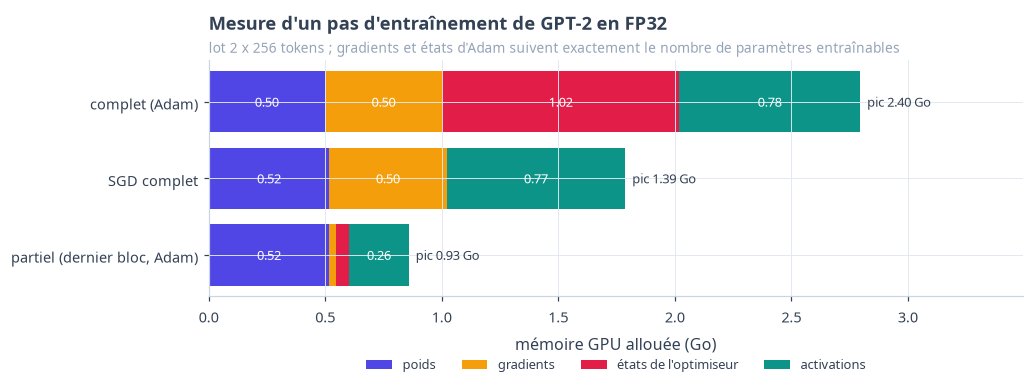

In [8]:
parts = ["poids", "gradients", "états de l'optimiseur", "activations"]
colors = [INDIGO, AMBER, ROSE, TEAL]
fig, ax = plt.subplots(figsize=(9.5, 3.8))
left = np.zeros(len(configs))
for p_, col in zip(parts, colors):
    vals = np.array([max(meas[c][p_], 0) / GB for c in configs])
    ax.barh(configs, vals, left=left, color=col, label=p_)
    for i, v in enumerate(vals):
        if v > 0.12:
            ax.text(left[i] + v / 2, i, f"{v:.2f}", ha="center", va="center", color="white", fontsize=8.5)
    left += vals
for i, c in enumerate(configs):
    ax.text(left[i] + 0.03, i, f"pic {meas[c]['pic'] / GB:.2f} Go", va="center", fontsize=8.5, color=SLATE)
ax.invert_yaxis(); ax.set_xlabel("mémoire GPU allouée (Go)"); ax.set_xlim(0, left.max() * 1.25)
ax.legend(ncol=4, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.2))
c7.title_sub(ax, "Mesure d'un pas d'entraînement de GPT-2 en FP32",
             "lot 2 x 256 tokens ; gradients et états d'Adam suivent exactement le nombre de paramètres entraînables")
plt.tight_layout(); plt.show()

Les poids, gradients et états mesurés retombent sur les prévisions à quelques pour cent
près ($124 \cdot 10^6 \times 4$ octets $\approx 0{,}5$ Go chacun, et le double pour les deux
états d'Adam). Avec SGD sans momentum, les états disparaissent ; en ne laissant que le
dernier bloc entraînable (7 M paramètres sur 124 M), gradients et états fondent, mais les
activations restent du même ordre : il faut encore propager le gradient jusqu'à ce bloc,
et la couche de sortie (logits sur 50 257 tokens) en consomme une bonne partie.
Notez que la somme des barres dépasse le pic : les activations sont libérées au fur et à
mesure que la passe arrière crée les gradients, les deux ne coexistent jamais en totalité.

**Expérience 2 : Qwen2.5-0.5B en BF16.** Un finetuning complet avec Adam demanderait
$0{,}49 \cdot 10^9 \times 8$ octets $\approx 4$ Go pour poids, gradients et états, sans
compter les activations : on reste sous notre budget en mesurant l'inférence et un pas de
finetuning **LoRA** (cours 3), où seuls 0,9 % des paramètres sont entraînables.

In [9]:
from peft import LoraConfig, get_peft_model


def run_qwen(seq, batch, lora=True, checkpointing=False):
    tok, model = c7.load_fresh(llm.SMALL)
    model.config.use_cache = False
    if checkpointing:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    if lora:
        model = get_peft_model(model, LoraConfig(r=8, lora_alpha=16, target_modules="all-linear", task_type="CAUSAL_LM"))
    ids = tok(texte, return_tensors="pt")["input_ids"][:, :seq].repeat(batch, 1).cuda()
    r = c7.measure_train_step(model, {"input_ids": ids, "labels": ids}, lambda ps: torch.optim.AdamW(ps, lr=1e-4))
    r["entraînables"] = sum(p.numel() for p in model.parameters() if p.requires_grad)
    del model; gc.collect(); torch.cuda.empty_cache()
    return r


def run_qwen_inference(seq, batch):
    tok, model = c7.load_fresh(llm.SMALL)
    ids = tok(texte, return_tensors="pt")["input_ids"][:, :seq].repeat(batch, 1).cuda()
    torch.cuda.synchronize(); base = torch.cuda.memory_allocated(); torch.cuda.reset_peak_memory_stats()
    with torch.no_grad():
        model(ids)
    r = {"poids": base, "pic": torch.cuda.max_memory_allocated()}
    del model; gc.collect(); torch.cuda.empty_cache()
    return r


inf = c7.gpu_retry(run_qwen_inference, 384, 1)
lo = c7.gpu_retry(run_qwen, 384, 1)
c7.log_vram("nb2 qwen lora")
V = 151936
logits_bytes = 384 * V * 4  # logits convertis en FP32 pour la perte
pd.DataFrame({"inférence (1 x 384 tokens)": [inf["poids"] / GB, np.nan, np.nan, inf["pic"] / GB],
              "pas LoRA r=8 (1 x 384 tokens)": [lo["poids"] / GB, lo["gradients"] / GB, lo["états de l'optimiseur"] / GB, lo["pic"] / GB]},
             index=["poids (Go)", "gradients (Go)", "états Adam (Go)", "pic (Go)"]).round(3).T.assign(
    **{"entraînables": [np.nan, f"{lo['entraînables'] / 1e6:.1f} M"]})

,poids (Go),gradients (Go),états Adam (Go),pic (Go),entraînables
inférence (1 x 384 tokens),1.013,NaN,NaN,1.136,NaN
pas LoRA r=8 (1 x 384 tokens),1.031,0.018,0.035,2.556,4.4 M


Les poids BF16 pèsent $\approx 1$ Go ($494 \cdot 10^6 \times 2$ octets ; les embeddings sont
partagés avec la couche de sortie). Avec LoRA, gradients et états ne pèsent que quelques
dizaines de Mo. Le pic est pourtant bien au-dessus des poids : ce sont les **activations**,
et en particulier les **logits**. Avec un vocabulaire de $V = 151\,936$ tokens, les logits
d'une séquence de 384 tokens convertis en FP32 pour calculer la perte occupent
$384 \times V \times 4$ octets, soit **environ 0,23 Go** à eux seuls, et la passe arrière
en crée des copies. C'est un poste souvent oublié des calculs « de coin de table » pour les
petits modèles à grand vocabulaire.

**Expérience 3 : gradient checkpointing.** Pour isoler les activations des **blocs
transformer** (celles que vise le checkpointing), on court-circuite la couche de sortie :
la perte est une fonction factice des états cachés du dernier bloc (moyenne de leurs
carrés), ce qui fait remonter le gradient à travers tous les blocs sans matérialiser les
logits. On mesure, pour une séquence de plus en plus longue (lot de 1), la mémoire et le
temps d'un pas LoRA, avec et sans recalcul des activations.

Logits FP32 de 384 tokens : 0.23 Go


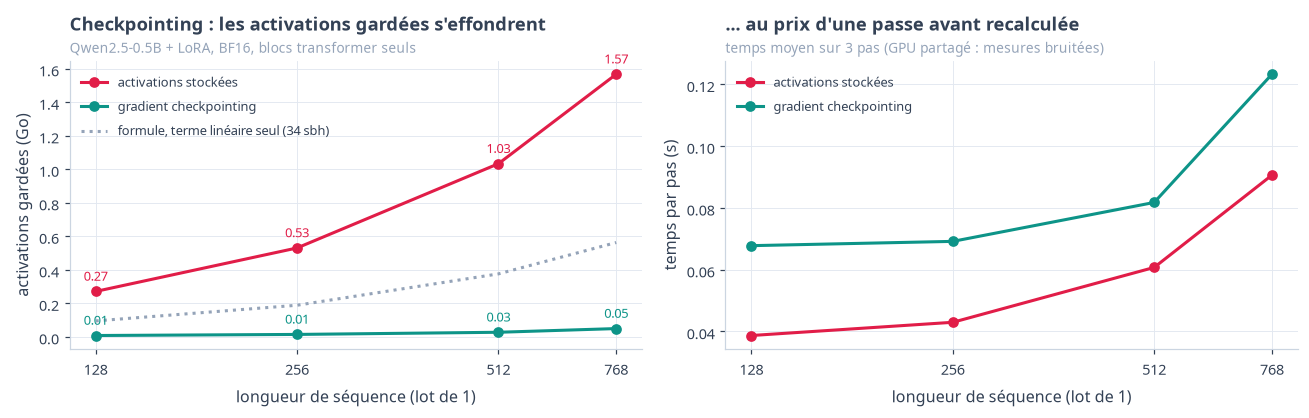

,séquence,checkpointing,activations (Go),pic (Go),temps par pas (s)
0,128,False,0.270,1.338,0.039
1,128,True,0.006,1.101,0.068
2,256,False,0.529,1.601,0.043
3,256,True,0.013,1.117,0.069
4,512,False,1.032,2.109,0.061
5,512,True,0.026,1.148,0.082
6,768,False,1.566,2.648,0.091
7,768,True,0.048,1.196,0.123


In [10]:
print(f"Logits FP32 de 384 tokens : {logits_bytes / GB:.2f} Go")


class _Out:
    def __init__(self, loss):
        self.loss = loss


class BackboneLoss(torch.nn.Module):
    """Enveloppe : passe dans les blocs du modèle et renvoie une perte factice sur les états cachés."""

    def __init__(self, causal_lm):
        super().__init__()
        self.backbone = causal_lm.model

    def forward(self, input_ids):
        h = self.backbone(input_ids=input_ids).last_hidden_state
        return _Out(h.float().pow(2).mean())


def run_blocks(seq, ck):
    tok, model = c7.load_fresh(llm.SMALL)
    model.config.use_cache = False
    if ck:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model = get_peft_model(model, LoraConfig(r=8, lora_alpha=16, target_modules="all-linear", task_type="CAUSAL_LM"))
    model.train()  # le checkpointing de transformers n'agit qu'en mode entraînement
    wrapped = BackboneLoss(model.get_base_model())
    ids = tok(texte * 3, return_tensors="pt")["input_ids"][:, :seq].cuda()
    torch.cuda.synchronize(); t = time.time()
    r = c7.measure_train_step(wrapped, {"input_ids": ids}, lambda ps: torch.optim.AdamW(ps, lr=1e-4), n_steps=3)
    r["temps par pas"] = (time.time() - t) / 3
    del model, wrapped; gc.collect(); torch.cuda.empty_cache()
    return r


ck_rows = []
for s_len in [128, 256, 512, 768]:
    for ck in [False, True]:
        r = c7.gpu_retry(run_blocks, s_len, ck)
        ck_rows.append({"séquence": s_len, "checkpointing": ck, "activations (Go)": r["activations"] / GB,
                        "pic (Go)": r["pic"] / GB, "temps par pas (s)": r["temps par pas"]})
ck_df = pd.DataFrame(ck_rows)
c7.log_vram("nb2 checkpointing")
spec_q = c7.MODEL_SPECS["Qwen2.5-0.5B"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for ck, col, lab in [(False, ROSE, "activations stockées"), (True, TEAL, "gradient checkpointing")]:
    sub = ck_df[ck_df.checkpointing == ck]
    axes[0].plot(sub["séquence"], sub["activations (Go)"], "o-", color=col, label=lab)
    for s_, v_ in zip(sub["séquence"], sub["activations (Go)"]):
        axes[0].annotate(f"{v_:.2f}", (s_, v_), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8.5, color=col)
    axes[1].plot(sub["séquence"], sub["temps par pas (s)"], "o-", color=col, label=lab)
seqs_q = np.array([128, 256, 512, 768])
axes[0].plot(seqs_q, [c7.activation_memory(spec_q, s_, 1) / GB * 34 / (34 + 5 * spec_q.heads * s_ / spec_q.hidden) for s_ in seqs_q],
             ":", color=GRAY, label="formule, terme linéaire seul (34 sbh)")
for ax in axes:
    ax.set_xscale("log", base=2); ax.set_xticks(seqs_q, [str(s_) for s_ in seqs_q]); ax.set_xlabel("longueur de séquence (lot de 1)")
axes[0].set_ylabel("activations gardées (Go)"); axes[0].legend(fontsize=8.5)
axes[1].set_ylabel("temps par pas (s)"); axes[1].legend(fontsize=8.5)
c7.title_sub(axes[0], "Checkpointing : les activations gardées s'effondrent", "Qwen2.5-0.5B + LoRA, BF16, blocs transformer seuls")
c7.title_sub(axes[1], "... au prix d'une passe avant recalculée", "temps moyen sur 3 pas (GPU partagé : mesures bruitées)")
plt.tight_layout(); plt.show()
ck_df.round(3)

Sans checkpointing, les activations gardées croissent linéairement avec la séquence
(l'attention de PyTorch, dite *SDPA*, ne stocke pas la matrice $s \times s$, d'où
l'absence de terme quadratique), à environ trois fois le terme $34\,sbh$ de la formule :
celle-ci a été établie pour GPT, alors que Qwen a une couche feed-forward plus large
(SwiGLU, $5{,}4\,h$) et des conversions en FP32 dans ses normalisations et adaptateurs.
Avec checkpointing, il ne reste que les entrées des 24 blocs ($2sbh$ octets chacun) :
un facteur de l'ordre de 20 à 30 en moins. En contrepartie, chaque pas refait une passe
avant pendant la passe arrière, d'où un temps par pas plus long. Sur un vrai finetuning de
petit modèle, n'oubliez pas que les **logits** (non concernés) peuvent rester le premier
poste.

> **À retenir.** Les formules prévoient très bien poids, gradients et états de
> l'optimiseur. Les activations sont plus difficiles à estimer (implémentation de
> l'attention, logits sur un grand vocabulaire) : **mesurez**. Le gradient checkpointing
> réduit la mémoire des activations au prix de calculs supplémentaires.